<a id="top"></a>
# House Sales: valutare un modello di regressione

Nell'esercitazione House Sales avete allenato un modello di regressione per prevedere il prezzo di vendita.
Qui ci concentriamo su come **valutare** le previsioni e su come **raccontare i numeri** al business.

<a id="indice"></a>
## Indice

- [Collegamento all'esercitazione House Sales](#collegamento-esercitazione)
- [Metriche fondamentali per la regressione](#metriche-regressione)
- [Esempio numerico con MAE, RMSE e R²](#esempio-metriche)
- [Applicazione guidata al vostro modello](#applicazione-guidata)


<a id="collegamento-esercitazione"></a>
## Collegamento all'esercitazione House Sales

Nel caso House Sales il target non è binario ma **continuo**: il prezzo di vendita della casa.
Il modello non risponde "sì/no", ma produce un **valore numerico** per ogni immobile.

Per capire se il PoC è credibile bisogna rispondere a domande del tipo:

- quanto sbagliamo in media, in euro;
- quanto pesa l'errore rispetto al prezzo medio delle case;
- quanto del "segnale" sul prezzo riusciamo a spiegare.


<a id="metriche-regressione"></a>
## Metriche fondamentali per la regressione

Si indicano con \(y_i\) i valori reali del prezzo e con \(\hat{y}_i\) le previsioni del modello, per \(i = 1, \dots, n\).

**1. Mean Absolute Error (MAE)**  
Errore medio assoluto, comodo da leggere in **euro**:

$ \text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i| $

Un MAE di 18.000 € significa che, in media, il modello sbaglia il prezzo di circa 18.000 €.

**2. Mean Squared Error (MSE) e Root Mean Squared Error (RMSE)**  
Penalizzano di più gli errori grandi; l'RMSE riporta l'unità di misura agli euro:

$ \text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \ $ 

$  \text{RMSE} = \sqrt{\text{MSE}} \ $ 

Quando si comunica al business è più naturale usare l'RMSE, perché è in euro come il MAE.

**3. Metriche percentuali (ad esempio MAPE)**  
Per dare una lettura relativa rispetto al valore della casa:

$  \text{MAPE} = \frac{100}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right| \ $ 

Se il MAPE è intorno al 6\%, si può dire che l'errore medio relativo è circa il 6\% del prezzo reale.

**4. Coefficiente di determinazione (R²)**  
Misura quanta parte della variabilità del prezzo viene spiegata dal modello:

$  R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2} \ $ 

dove \(\bar{y}\) è la media dei prezzi reali.
Un R² pari a 0.80 indica che il modello spiega circa l'80\% della variabilità osservata nei prezzi.

<div style="background-color:#f5f5f5; padding:10px; border-left:4px solid #999;">
<strong>Nota importante</strong><br>
Nella comunicazione al business ha senso combinare una <em>metrica in euro</em> (MAE o RMSE)
con una <em>metrica percentuale</em> (MAPE) o con l'R², per collegare l'errore sia in valore assoluto
sia in termini relativi.
</div>


## STEP 1: Valutazione dei modelli 

Preparando il dataset come nell'esercitazione precedente allena Linear Regression e calcolate tutte le metriche definite sopra.


In [1]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import numpy as np


import pandas as pd
from sklearn.datasets import fetch_openml

# Scarica il dataset House Sales da OpenML
raw = fetch_openml(data_id=42092, as_frame=True)  # House sales
house = raw.frame.copy()

print("Dimensioni del dataset (righe, colonne):", house.shape)
house.head()

#PARTE 2
from sklearn import set_config
from sklearn.model_selection import train_test_split
set_config(transform_output="pandas")


# rimuovere le colonne che non utilizzerò nel modello
colonne_da_rimuovere = [
    "date",
    "zipcode",
    "lat",
    "long",
    "yr_built",
    "yr_renovated"
]

# Separazione tra feature (X) e target (y)
X = house.drop(columns=["price", *colonne_da_rimuovere])
y = house["price"]

# Suddivisione: 70% training, 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Dimensioni di X_train:", X_train.shape)
print("Dimensioni di X_test:", X_test.shape)

#queste sono vuote, non ancora y fitted
print("Dimensioni di y_train:", y_train.shape)
print("Dimensioni di y_test:", y_test.shape)


#PARTE 3
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# Verifica che tutte le feature siano numeriche
colonne_non_numeriche = X_train.select_dtypes(exclude="number").columns.tolist()
print("Colonne non numeriche:", colonne_non_numeriche)

# Pipeline di preprocessing
preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Adatta sul training set e trasforma entrambi i set
X_train_preprocessed = preprocessing.fit_transform(X_train)
X_test_preprocessed = preprocessing.transform(X_test)

print("Dimensioni X_train preprocessato:", X_train_preprocessed.shape)
print("Dimensioni X_test preprocessato:", X_test_preprocessed.shape)



#PARTE 4
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression

modello = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("regression", LinearRegression())
])

# Addestramento
modello.fit(X_train, y_train)

# Previsioni sul test set
y_pred = modello.predict(X_test)

print(y_pred[:10])

Dimensioni del dataset (righe, colonne): (21613, 20)
Dimensioni di X_train: (15129, 13)
Dimensioni di X_test: (6484, 13)
Dimensioni di y_train: (15129,)
Dimensioni di y_test: (6484,)
Colonne non numeriche: []
Dimensioni X_train preprocessato: (15129, 13)
Dimensioni X_test preprocessato: (6484, 13)
[ 553966.33266221  752322.13729963 1251867.86602962 1519499.43796542
  728043.44270647  340115.03265771  767415.64039654  499176.76316144
  445794.67807932  323528.86690404]


## STEP 2: Migliora

Si può migliorare solo quello che possiamo misurare. Ora che sappiamo misurarlo proviamo diversi modelli e vediamo quale ottiene migliori performance.

Allena anche Random Forest Regressor e confronta le metriche

In [3]:
from sklearn.ensemble import RandomForestRegressor

modello2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("regression", RandomForestRegressor(n_estimators=100, random_state=42))
])

# Addestramento
modello2.fit(X_train, y_train)

# Previsioni sul test set
y_pred = modello2.predict(X_test)

print(y_pred[:10])

[ 464398.11  872701.5   982139.   1389269.9   765904.39  331008.2
  523012.5   617722.02  400245.08  527623.54]


## STEP 3: Spiega

Usa PFI e SHAP per verificare quali sono le varibaili più importanti e come impattano. Scrivi due righe per riassumere.

In [4]:
import shap
from sklearn.inspection import permutation_importance
# Previsioni sullo stesso test set
y_pred_lineare = modello.predict(X_test)
y_pred_foresta = modello2.predict(X_test)

# Calcolo delle metriche per ciascun modello
risultati = []
for nome, predizioni in [
    ("Regressione lineare", y_pred_lineare),
    ("Random Forest", y_pred_foresta)
]:
    mse = mean_squared_error(y_test, predizioni)
    risultati.append({
        "Modello": nome,
        "MAE": mean_absolute_error(y_test, predizioni),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_test, predizioni),
        "MAPE (%)": mean_absolute_percentage_error(y_test, predizioni) * 100
    })

pd.DataFrame(risultati).set_index("Modello").round(3)


c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,MAE,MSE,RMSE,R²,MAPE (%)
Modello,,,,,
Regressione lineare,154646.958,5.662022e+10,237950.035,0.608,31.636
Random Forest,128100.965,4.463853e+10,211278.314,0.691,25.771


,MAE,RMSE,R²,MAPE (%)
Modello,,,,
Regressione lineare,154646.958,237950.035,0.608,31.636
Random Forest,128100.965,211278.314,0.691,25.771


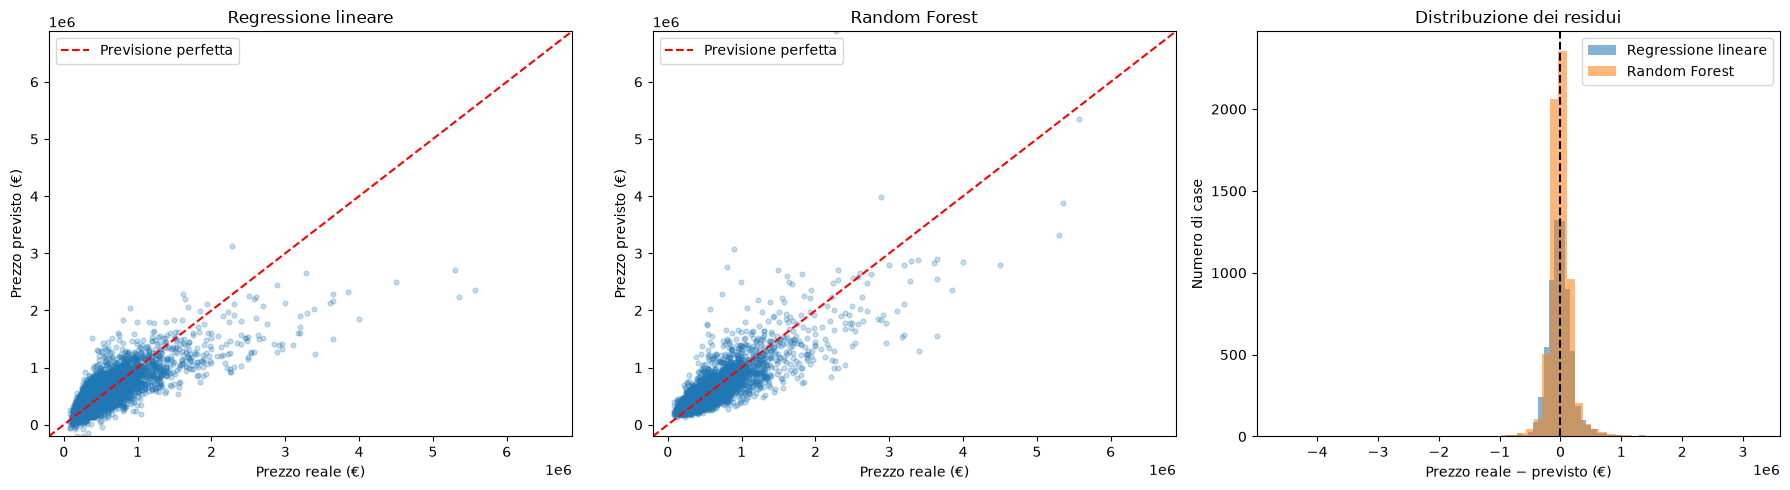

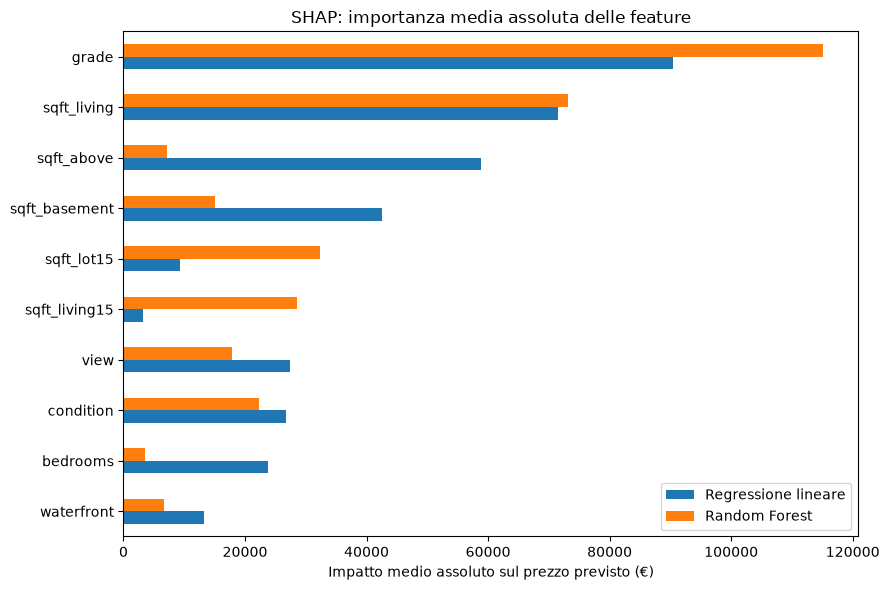

In [5]:
import matplotlib.pyplot as plt

# Metriche sul test set
confronto = pd.DataFrame([
    {
        "Modello": nome,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100
    }
    for nome, pred in [
        ("Regressione lineare", y_pred_lineare),
        ("Random Forest", y_pred_foresta)
    ]
]).set_index("Modello")

display(confronto.round(3))

# Affidabilità: valori reali vs previsti e distribuzione dei residui
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

limite_min = min(y_test.min(), y_pred_lineare.min(), y_pred_foresta.min())
limite_max = max(y_test.max(), y_pred_lineare.max(), y_pred_foresta.max())

for ax, nome, pred in [
    (axes[0], "Regressione lineare", y_pred_lineare),
    (axes[1], "Random Forest", y_pred_foresta)
]:
    ax.scatter(y_test, pred, alpha=0.25, s=12)
    ax.plot([limite_min, limite_max], [limite_min, limite_max],
            "r--", label="Previsione perfetta")
    ax.set(xlabel="Prezzo reale (€)", ylabel="Prezzo previsto (€)",
           title=nome, xlim=(limite_min, limite_max),
           ylim=(limite_min, limite_max))
    ax.legend()

axes[2].hist(y_test - y_pred_lineare, bins=50, alpha=0.55,
             label="Regressione lineare")
axes[2].hist(y_test - y_pred_foresta, bins=50, alpha=0.55,
             label="Random Forest")
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set(title="Distribuzione dei residui",
            xlabel="Prezzo reale − previsto (€)", ylabel="Numero di case")
axes[2].legend()

plt.tight_layout()
plt.show()

# SHAP: confronto dell'importanza globale delle feature
background = X_train_preprocessed.sample(
    min(100, len(X_train_preprocessed)), random_state=42
)
campione = X_test_preprocessed.sample(
    min(500, len(X_test_preprocessed)), random_state=42
)

explainer_lineare = shap.LinearExplainer(
    modello.named_steps["regression"], background
)
explainer_foresta = shap.TreeExplainer(
    modello2.named_steps["regression"]
)

def valori_shap(explainer, dati):
    valori = explainer.shap_values(dati)
    if isinstance(valori, list):
        valori = valori[0]
    valori = np.asarray(valori)
    if valori.ndim == 3 and valori.shape[-1] == 1:
        valori = valori[:, :, 0]
    return valori

shap_lineare = valori_shap(explainer_lineare, campione)
shap_foresta = valori_shap(explainer_foresta, campione)

importanze = pd.DataFrame({
    "Regressione lineare": np.abs(shap_lineare).mean(axis=0),
    "Random Forest": np.abs(shap_foresta).mean(axis=0)
}, index=campione.columns)

top_feature = importanze.max(axis=1).nlargest(10).sort_values().index
importanze.loc[top_feature].plot.barh(figsize=(9, 6))
plt.title("SHAP: importanza media assoluta delle feature")
plt.xlabel("Impatto medio assoluto sul prezzo previsto (€)")
plt.tight_layout()
plt.show()

## Extra:

Non sollo l'algoritmo impatta sulle performance, prova a settare diversamente i parametri del modello (iperparametri) come max_depth per Random Forest e verifica se le performance migliorano. Registra la performance migliore che sei riuscito ad ottenere. 

In [6]:
from sklearn.model_selection import GridSearchCV

# Confronta diverse profondità mantenendo invariati gli altri parametri
ricerca = GridSearchCV(
    estimator=modello2,
    param_grid={"regression__max_depth": [None, 8, 12, 16, 20]},
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

ricerca.fit(X_train, y_train)
modello_migliore = ricerca.best_estimator_
y_pred_migliore = modello_migliore.predict(X_test)

print("Miglior max_depth:", ricerca.best_params_["regression__max_depth"])
print(f"RMSE media in cross-validation: {-ricerca.best_score_:,.2f} €")

# Confronta il modello iniziale e quello ottimizzato sul test set
confronto_iperparametri = pd.DataFrame([
    {
        "Modello": nome,
        "MAE (€)": mean_absolute_error(y_test, pred),
        "RMSE (€)": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100
    }
    for nome, pred in [
        ("Random Forest iniziale", y_pred_foresta),
        ("Random Forest ottimizzata", y_pred_migliore)
    ]
]).set_index("Modello")

display(confronto_iperparametri.round(3))

riga_migliore = confronto_iperparametri.loc["Random Forest ottimizzata"]
print(
    f"Performance migliore sul test set: RMSE {riga_migliore['RMSE (€)']:,.2f} €, "
    f"MAE {riga_migliore['MAE (€)']:,.2f} €, R² {riga_migliore['R²']:.3f}."
)

Miglior max_depth: 16
RMSE media in cross-validation: 193,838.00 €


,MAE (€),RMSE (€),R²,MAPE (%)
Modello,,,,
Random Forest iniziale,128100.965,211278.314,0.691,25.771
Random Forest ottimizzata,128140.359,210917.968,0.692,25.757


Performance migliore sul test set: RMSE 210,917.97 €, MAE 128,140.36 €, R² 0.692.


In [9]:
X_train

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,sqft_living15,sqft_lot15
167,4,2.50,2680,4499,2.0,0,0,3,9,2680,0,2920,4500
12412,4,1.75,2340,5080,1.0,0,0,5,7,1170,1170,1270,3270
7691,4,2.25,2190,9020,2.0,0,0,3,8,2190,0,2170,8400
12460,2,1.75,2260,280962,2.0,0,2,3,9,1890,370,2860,219542
9099,4,1.75,2110,265716,1.0,0,0,4,8,2110,0,2110,110597
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11964,3,1.50,1000,6914,1.0,0,0,3,7,1000,0,1000,6947
21575,3,2.50,3087,5002,2.0,0,0,3,8,3087,0,2927,5183
5390,3,2.50,2120,4780,2.0,0,0,3,7,2120,0,1690,2650
860,1,0.75,380,15000,1.0,0,0,3,5,380,0,1170,15000
